# Predicción del precio de la vivienda en California
**Análisis completo de datos + Machine Learning, de principio a fin**

Este notebook recorre el flujo de trabajo típico de un proyecto de datos:

1. Entender el problema y los datos
2. Revisar la calidad de los datos
3. Análisis exploratorio (EDA)
4. Estadística descriptiva e inferencial
5. Modelos de Machine Learning y comparación
6. Evaluación final e interpretación
7. Conclusiones y limitaciones

> **Cómo leerlo si eres principiante:** cada sección explica *qué* se hace y *por qué*, antes del código.
> Ejecuta las celdas en orden (`Shift + Enter`).

## 1. El problema

Cada fila del dataset es un **distrito censal** de California (datos del censo de 1990).
Queremos **predecir el valor mediano de las viviendas** (`median_house_value`) a partir de variables como el ingreso, la ubicación o la antigüedad de las casas.

En Machine Learning esto se llama un problema de **regresión supervisada**: predecimos un número (el precio) usando ejemplos donde ya conocemos la respuesta.

| Variable | Significado |
|---|---|
| `longitude`, `latitude` | Ubicación del distrito |
| `housing_median_age` | Edad mediana de las casas (años) |
| `total_rooms`, `total_bedrooms` | Habitaciones y dormitorios totales del distrito |
| `population`, `households` | Habitantes y hogares |
| `median_income` | Ingreso mediano (en decenas de miles de USD) |
| `ocean_proximity` | Cercanía al océano (categoría) |
| **`median_house_value`** | **Variable objetivo (lo que queremos predecir)** |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # permite importar la carpeta src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.config import TARGET, FIG_DIR, TABLE_DIR
from src.data import load_data, quality_report, add_features, censored_share
from src import eda, stats as st, models as ml

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

## 2. Carga y calidad de los datos

In [2]:
df_raw = load_data()
print(f"Filas: {df_raw.shape[0]:,}  |  Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 20,640  |  Columnas: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.00,880.00,129.00,322.00,126.00,8.33,"452,600.00",NEAR BAY
1,-122.22,37.86,21.00,"7,099.00","1,106.00","2,401.00","1,138.00",8.30,"358,500.00",NEAR BAY
2,-122.24,37.85,52.00,"1,467.00",190.00,496.00,177.00,7.26,"352,100.00",NEAR BAY
3,-122.25,37.85,52.00,"1,274.00",235.00,558.00,219.00,5.64,"341,300.00",NEAR BAY
4,-122.25,37.85,52.00,"1,627.00",280.00,565.00,259.00,3.85,"342,200.00",NEAR BAY


In [3]:
quality_report(df_raw)

,tipo,nulos,pct_nulos,unicos
longitude,float64,0,0.00,844
latitude,float64,0,0.00,862
housing_median_age,float64,0,0.00,52
total_rooms,float64,0,0.00,5926
total_bedrooms,float64,207,1.00,1923
population,float64,0,0.00,3888
households,float64,0,0.00,1815
median_income,float64,0,0.00,12928
median_house_value,float64,0,0.00,3842
ocean_proximity,str,0,0.00,5


**Qué observamos:**
- Solo `total_bedrooms` tiene valores nulos (≈1 %). Son pocos, así que los **imputaremos con la mediana** dentro del pipeline de modelado (y no antes, para evitar *fuga de datos*, ver sección 5).
- `ocean_proximity` es texto (categórica): habrá que convertirla a números para los modelos (*one-hot encoding*).

In [4]:
print(f"Distritos con precio topado en el máximo (500,001): {censored_share(df_raw):.1%}")
df_raw[TARGET].describe()

Distritos con precio topado en el máximo (500,001): 4.7%


count    20,640.00
mean    206,855.82
std     115,395.62
min      14,999.00
25%     119,600.00
50%     179,700.00
75%     264,725.00
max     500,001.00
Name: median_house_value, dtype: float64

⚠️ **Hallazgo importante:** el 4,7 % de los distritos tiene exactamente el precio máximo del dataset: el valor está **censurado** (topado), no es el precio real. Esto limitará cuánto podemos acertar en las viviendas más caras. Lo retomamos en las conclusiones.

## 3. Feature engineering (crear variables nuevas)

Los totales (`total_rooms`, `population`...) dependen del *tamaño* del distrito, no dicen mucho por sí solos.
Las **razones por hogar** son más comparables entre distritos:
- `rooms_per_household`: habitaciones por hogar
- `bedrooms_per_room`: proporción de dormitorios sobre el total de habitaciones
- `population_per_household`: personas por hogar (hacinamiento)

In [5]:
df = add_features(df_raw)
df[["rooms_per_household", "bedrooms_per_room", "population_per_household"]].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,"20,640.00","20,433.00","20,640.00"
mean,5.43,0.21,3.07
std,2.47,0.06,10.39
min,0.85,0.10,0.69
25%,4.44,0.18,2.43
50%,5.23,0.20,2.82
75%,6.05,0.24,3.28
max,141.91,1.00,"1,243.33"


## 4. Análisis exploratorio (EDA)

Antes de modelar hay que *mirar* los datos. Buscamos distribuciones raras, relaciones entre variables y patrones geográficos.

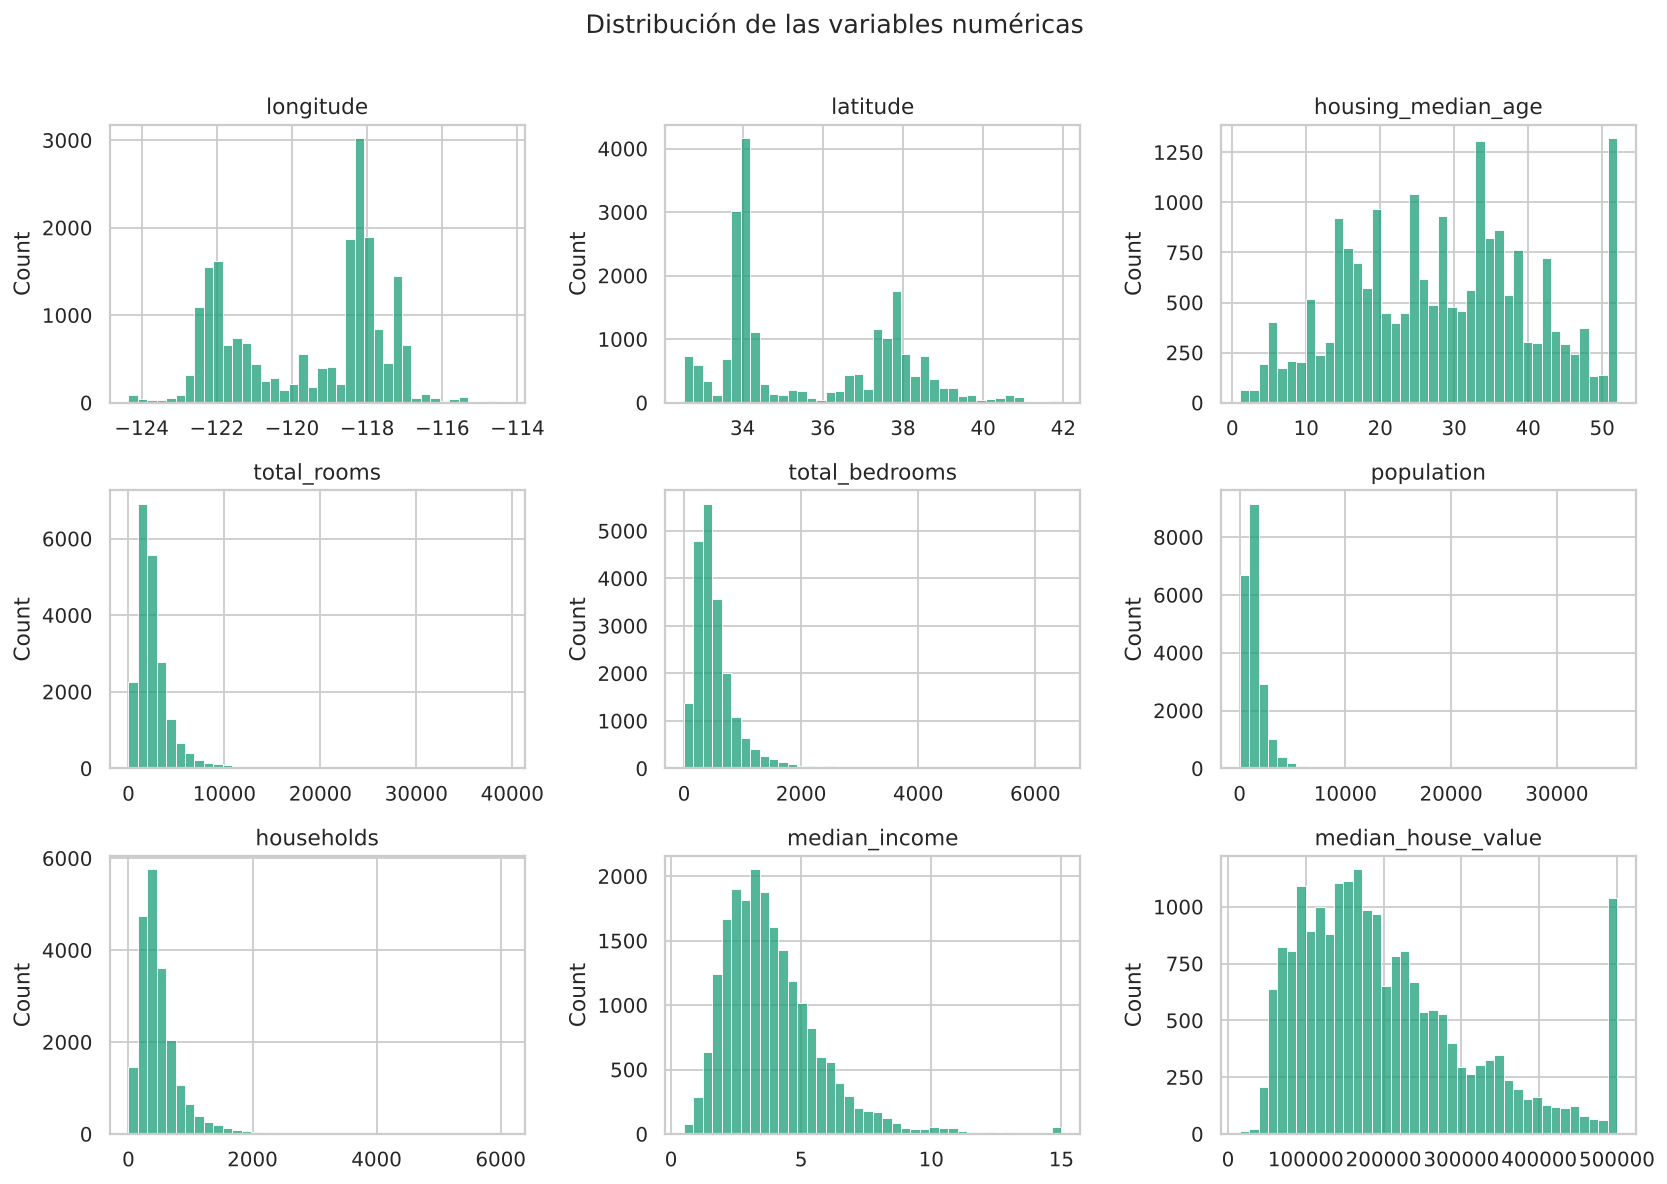

In [6]:
eda.run_eda(df)   # genera y guarda todas las figuras en reports/figures
display(Image(FIG_DIR / "02_distribuciones.png"))

**Lectura:** varias variables (`total_rooms`, `population`, `households`) tienen una cola larga hacia la derecha: pocos distritos enormes y muchos pequeños. Eso se llama **asimetría positiva**. También se aprecia el tope de 500,001 en el precio.

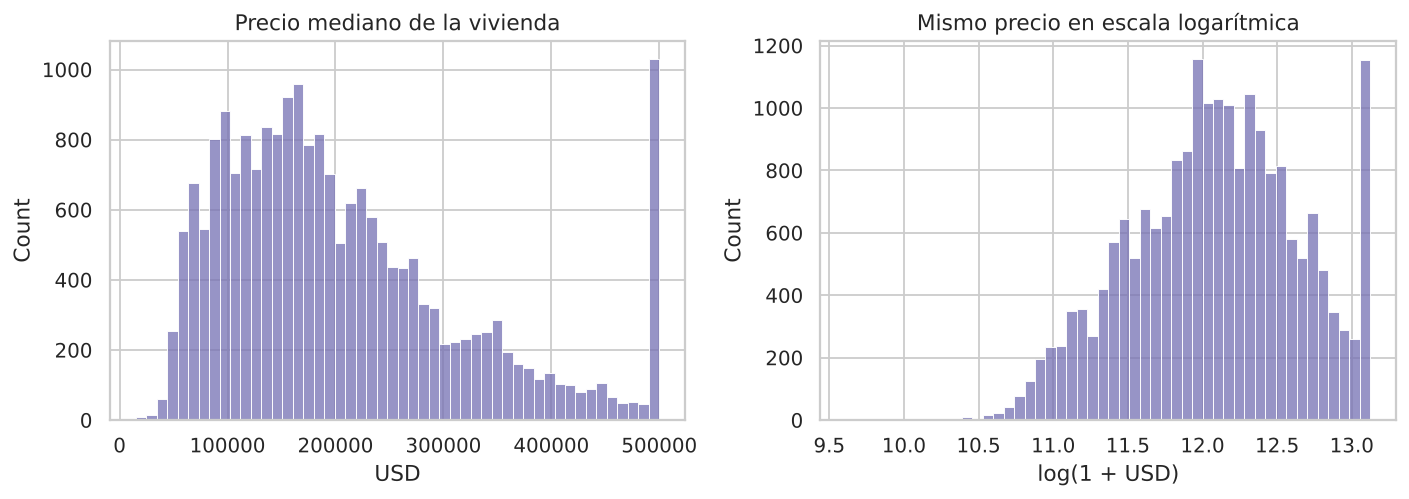

In [7]:
display(Image(FIG_DIR / "03_target.png"))

El precio tiene asimetría positiva; con escala logarítmica se ve más simétrico, algo común en precios e ingresos.

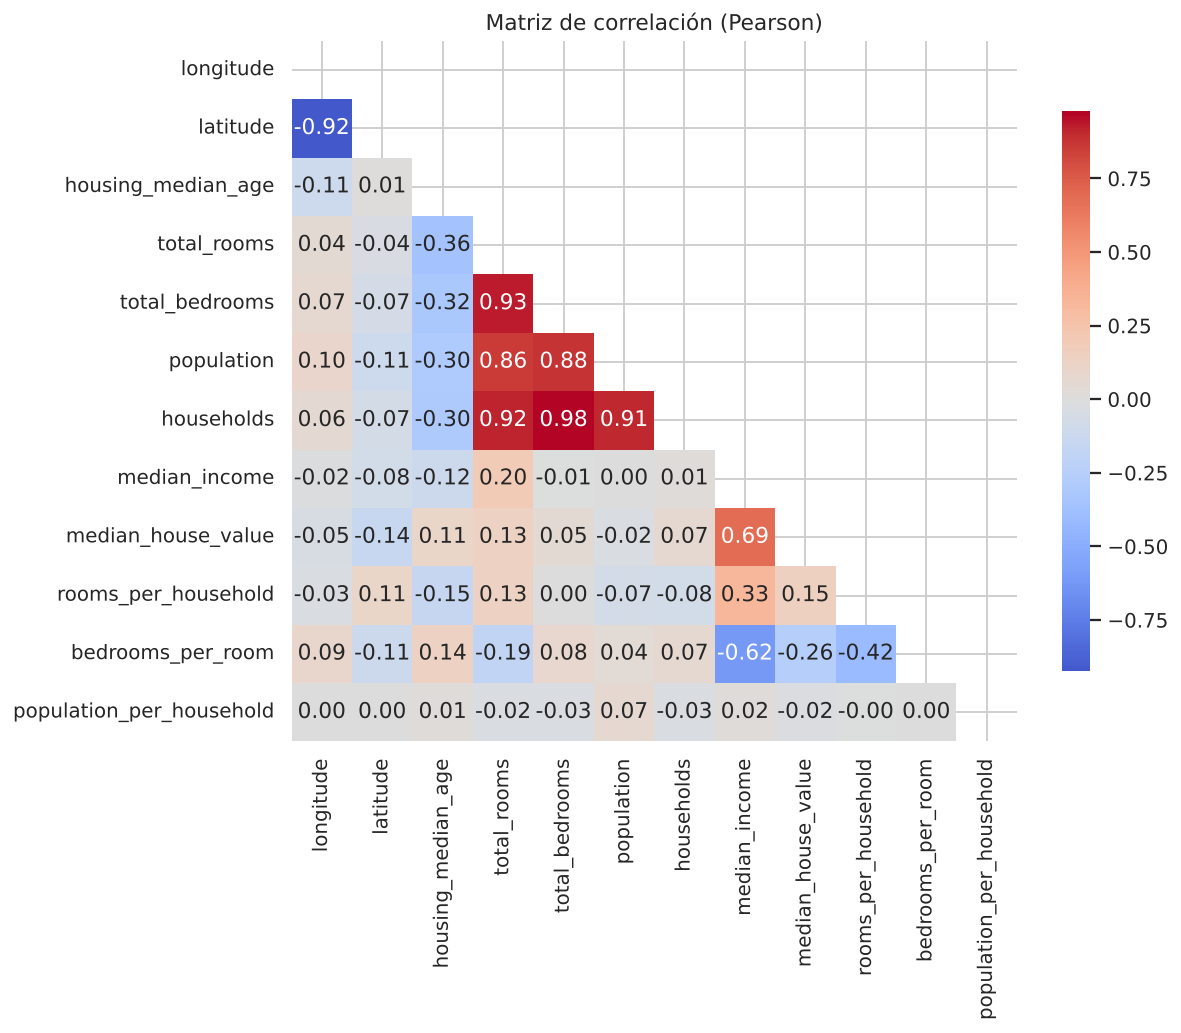

In [8]:
display(Image(FIG_DIR / "04_correlacion.png"))

**Lectura:** `median_income` es, por mucho, la variable más correlacionada con el precio (r ≈ 0,69). Ojo: **correlación no implica causalidad**; además, la correlación de Pearson solo mide relaciones *lineales*.

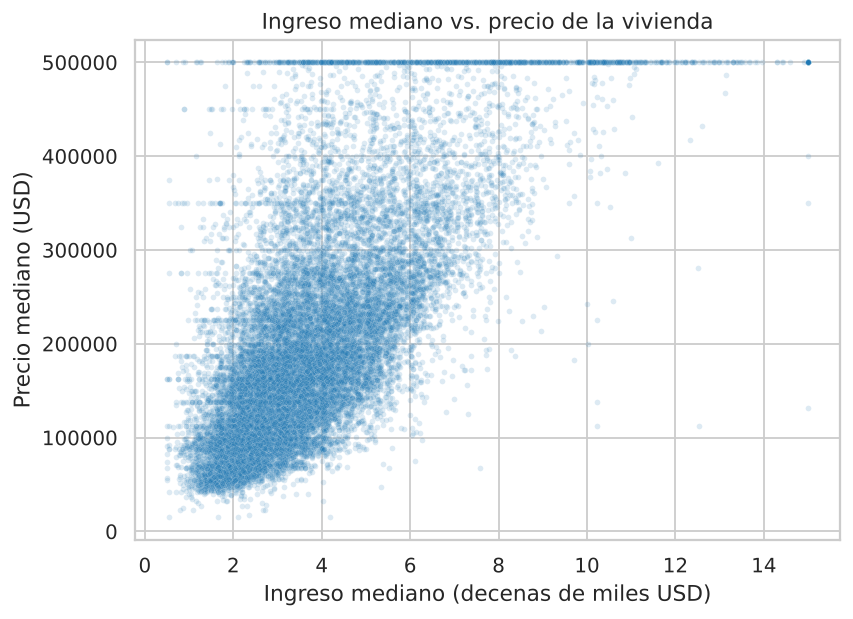

In [9]:
display(Image(FIG_DIR / "05_ingreso_vs_precio.png"))

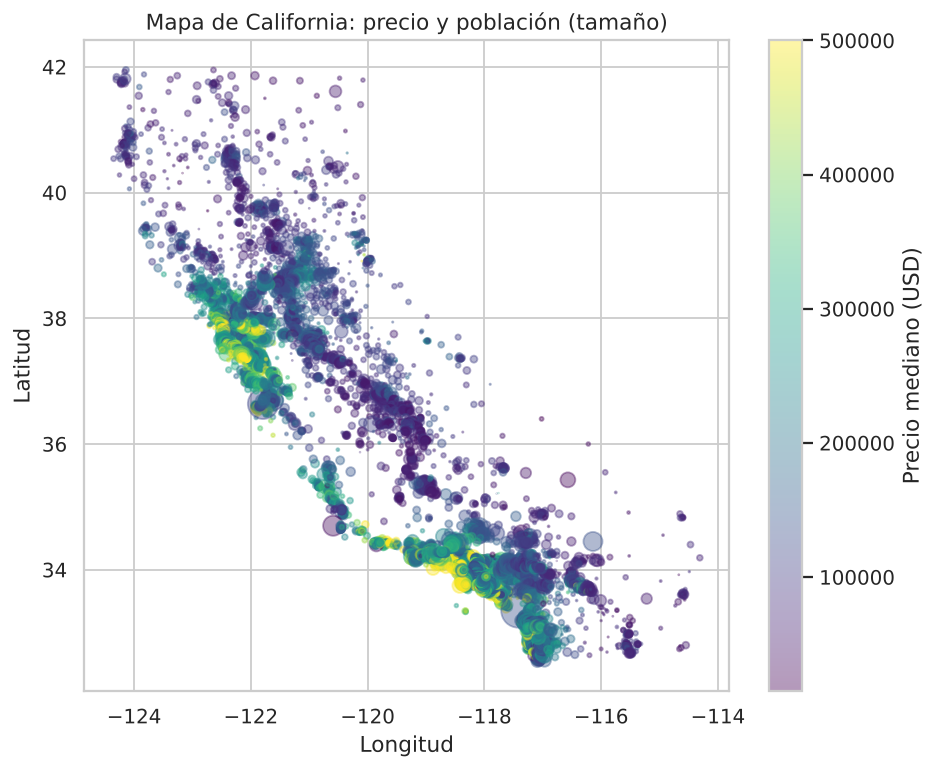

In [10]:
display(Image(FIG_DIR / "06_mapa_precios.png"))

**Lectura:** los distritos más caros se concentran en la costa, sobre todo en la **Bahía de San Francisco** y el área de **Los Ángeles / San Diego**. La ubicación importa mucho, algo que el modelo lineal simple captura mal y los modelos de árboles capturan bien.

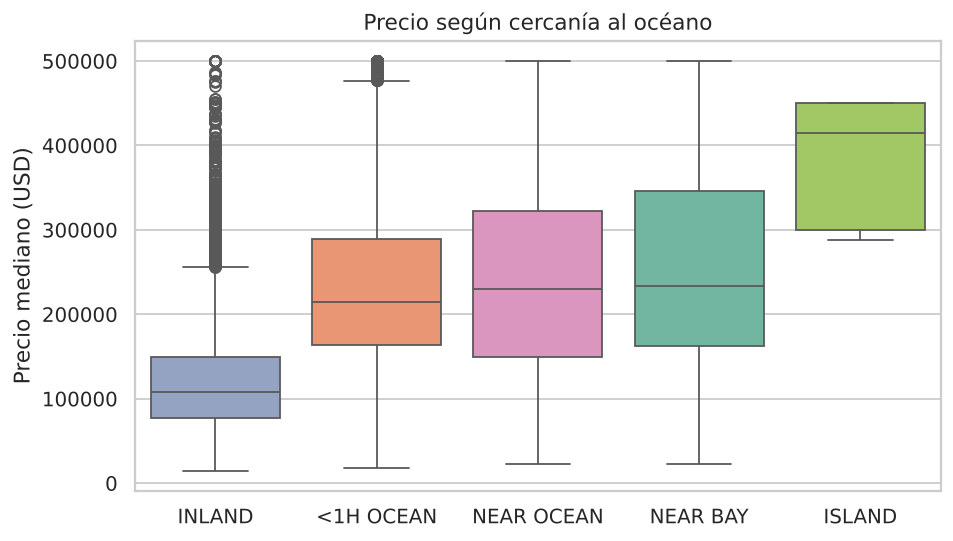

In [11]:
display(Image(FIG_DIR / "07_precio_por_cercania.png"))

## 5. Estadística descriptiva e inferencial

### 5.1 Descriptiva
Resumen numérico: media, mediana, desviación estándar, asimetría y curtosis.

In [12]:
res = st.save_all(df)
res["descriptivas"]

,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,curtosis
longitude,"20,640.00",-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31,-118.49,-0.30,-1.33
latitude,"20,640.00",35.63,2.14,32.54,33.93,34.26,37.71,41.95,34.26,0.47,-1.12
housing_median_age,"20,640.00",28.64,12.59,1.00,18.00,29.00,37.00,52.00,29.00,0.06,-0.80
total_rooms,"20,640.00","2,635.76","2,181.61",2.00,"1,447.75","2,127.00","3,148.00","39,320.00","2,127.00",4.15,32.63
total_bedrooms,"20,433.00",537.87,421.38,1.00,296.00,435.00,647.00,"6,445.00",435.00,3.46,21.99
population,"20,640.00","1,425.48","1,132.46",3.00,787.00,"1,166.00","1,725.00","35,682.00","1,166.00",4.94,73.55
households,"20,640.00",499.54,382.33,1.00,280.00,409.00,605.00,"6,082.00",409.00,3.41,22.06
median_income,"20,640.00",3.87,1.90,0.50,2.56,3.54,4.74,15.00,3.54,1.65,4.95
median_house_value,"20,640.00","206,855.82","115,395.62","14,999.00","119,600.00","179,700.00","264,725.00","500,001.00","179,700.00",0.98,0.33
rooms_per_household,"20,640.00",5.43,2.47,0.85,4.44,5.23,6.05,141.91,5.23,20.70,879.35


Si la **media** es bastante mayor que la **mediana**, la distribución tiene cola derecha (asimetría > 0).

### 5.2 Correlaciones con el precio
**Pearson** mide la relación lineal; **Spearman** mide si la relación es creciente/decreciente aunque no sea una recta. El p-valor indica si la correlación es distinguible de cero (con 20 000 filas casi todo es "significativo": fíjate más en el *tamaño* de r que en el p-valor).

In [13]:
res["correlaciones"]

,variable,pearson_r,p_pearson,spearman_rho,p_spearman
0,median_income,0.69,0.00,0.68,0.00
1,bedrooms_per_room,-0.26,0.00,-0.33,0.00
2,rooms_per_household,0.15,0.00,0.26,0.00
3,latitude,-0.14,0.00,-0.17,0.00
4,total_rooms,0.13,0.00,0.21,0.00
5,housing_median_age,0.11,0.00,0.08,0.00
6,households,0.06,0.00,0.11,0.00
7,total_bedrooms,0.05,0.00,0.09,0.00
8,longitude,-0.05,0.00,-0.07,0.00
9,population,-0.03,0.00,0.00,0.68


### 5.3 Intervalos de confianza
Un **intervalo de confianza al 95 %** da un rango plausible para la media poblacional. Intervalos que no se solapan sugieren diferencias reales entre grupos.

In [14]:
res["ic_por_grupo"]

,ocean_proximity,n,media,ic95_inf,ic95_sup
0,INLAND,6551,"124,805.00","123,110.00","126,501.00"
1,<1H OCEAN,9136,"240,084.00","237,908.00","242,261.00"
2,NEAR OCEAN,2658,"249,434.00","244,776.00","254,092.00"
3,NEAR BAY,2290,"259,212.00","254,179.00","264,245.00"
4,ISLAND,5,"380,440.00","280,412.00","480,468.00"


Observa el grupo **ISLAND**: solo 5 distritos, por eso su intervalo es enorme. Con tan pocos datos no se puede concluir mucho.

### 5.4 Pruebas de hipótesis
**H₀ (hipótesis nula):** el precio medio es igual entre las categorías de cercanía al océano.
**H₁:** al menos una categoría difiere.

- **ANOVA**: compara varias medias (supone aproximadamente normalidad).
- **Kruskal-Wallis**: alternativa que no supone normalidad.
- **t de Welch**: compara dos grupos sin suponer varianzas iguales. Se acompaña del **tamaño del efecto (d de Cohen)**: |d| ≈ 0,2 es pequeño, 0,5 medio, 0,8 grande.

In [15]:
res["pruebas"]

,prueba,estadistico,p_valor,efecto
0,ANOVA (todas las categorías),"1,612.14",0.00,NaN
1,Kruskal-Wallis (todas),"6,634.56",0.00,NaN
2,t de Welch INLAND vs <1H OCEAN,-81.91,0.00,-1.24


**Interpretación:** los p-valores son prácticamente 0 → rechazamos H₀: el precio **sí** cambia según la cercanía al océano. Y el efecto no es solo "significativo": con d ≈ −1,2 es **muy grande** (los distritos del interior son mucho más baratos). Recuerda: significancia estadística ≠ importancia práctica; por eso reportamos el tamaño del efecto.

### 5.5 Regresión lineal con statsmodels (OLS)
Aquí no buscamos predecir, sino **interpretar**: cuánto cambia el precio, en promedio, por cada unidad de cada variable manteniendo las demás constantes.

In [16]:
print(res["ols"].summary())

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.598
Method:                 Least Squares   F-statistic:                     3790.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:27:15   Log-Likelihood:            -2.5785e+05
No. Observations:               20433   AIC:                         5.157e+05
Df Residuals:                   20424   BIC:                         5.158e+05
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

**Cómo leerlo:** `coef` = cambio esperado en el precio (USD) por unidad de la variable; `P>|z|` = p-valor; `[0.025, 0.975]` = intervalo de confianza al 95 %. Por ejemplo, cada punto extra de `median_income` (10 000 USD de ingreso) se asocia con ≈ 38 000 USD más de valor de vivienda, controlando por el resto. Usamos errores estándar robustos (HC3) porque la varianza de los errores no es constante.

## 6. Machine Learning

### 6.1 Separar entrenamiento y prueba
Dividimos el 80 % de los datos para **entrenar** y el 20 % para **probar**. El set de prueba se guarda "bajo llave" hasta el final: simula datos nuevos que el modelo nunca vio. Si evaluáramos en los mismos datos con los que entrenamos, veríamos un resultado optimista y engañoso (*sobreajuste* u *overfitting*).

In [17]:
X_train, X_test, y_train, y_test = ml.split(df)
print(f"Entrenamiento: {len(X_train):,} filas | Prueba: {len(X_test):,} filas")

Entrenamiento: 16,512 filas | Prueba: 4,128 filas


### 6.2 Preprocesamiento dentro de un *pipeline*
Un `Pipeline` encadena el preprocesamiento y el modelo. Esto evita la **fuga de datos** (*data leakage*): la mediana para imputar o la media para estandarizar se calculan **solo con el set de entrenamiento** en cada paso de validación.

- Numéricas: imputar nulos con la mediana → estandarizar (media 0, desviación 1)
- Categóricas: one-hot encoding (una columna 0/1 por categoría)

### 6.3 Comparar modelos con validación cruzada
Probamos modelos de complejidad creciente. La **validación cruzada (5 folds)** divide el train en 5 partes, entrena con 4 y valida con 1, rotando; así obtenemos una estimación más estable del error.

- **Baseline:** predice siempre la media. Es el piso mínimo que cualquier modelo debe superar.
- **Regresión lineal / Ridge:** modelos lineales.
- **Random Forest:** muchos árboles de decisión que "votan".
- **Gradient Boosting:** árboles construidos en secuencia, cada uno corrigiendo los errores del anterior.

Métrica: **RMSE** (raíz del error cuadrático medio), en USD: el error "típico" de predicción, penalizando más los errores grandes.

In [18]:
cv_table = ml.compare_models(X_train, y_train)
ml.plot_model_comparison(cv_table)
cv_table

,modelo,rmse_cv_media,rmse_cv_std
0,Gradient Boosting,"46,888.19",628.10
1,Random Forest,"50,134.46",620.15
2,Ridge,"67,847.59","1,564.23"
3,Regresión lineal,"67,848.83","1,562.85"
4,Baseline (media),"115,618.56","1,283.04"


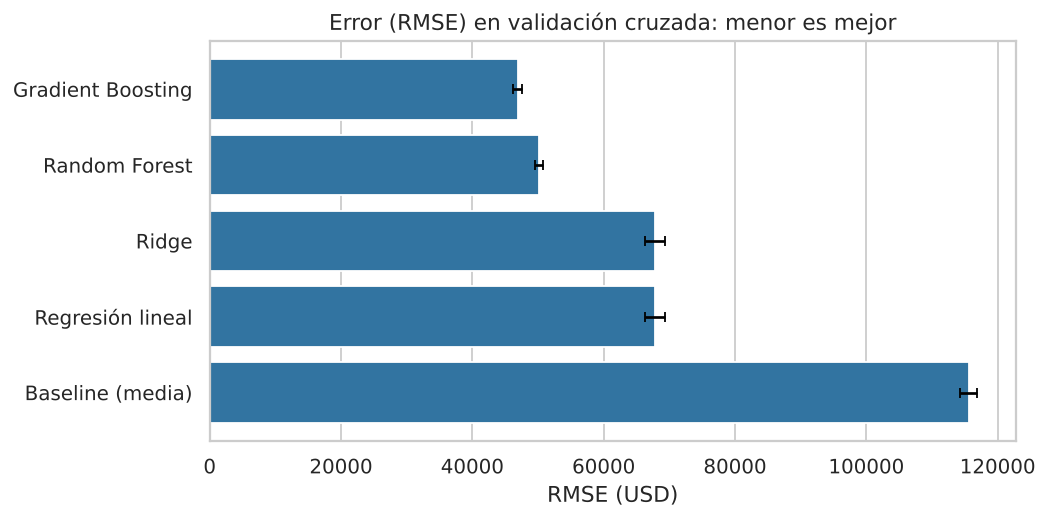

In [19]:
display(Image(FIG_DIR / "08_comparacion_modelos.png"))

Los modelos de árboles reducen el error muy por debajo de los lineales: la relación entre variables (sobre todo ubicación) **no es lineal**.

### 6.4 Ajuste de hiperparámetros
Los **hiperparámetros** son los "diales" del modelo que no se aprenden de los datos (tasa de aprendizaje, número de hojas...). Hacemos una **búsqueda aleatoria** con validación cruzada sobre el mejor modelo.

In [20]:
search = ml.tune_boosting(X_train, y_train)
print("Mejor RMSE en CV:", round(-search.best_score_, 1))
{k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}

Mejor RMSE en CV: 46215.6


{'l2_regularization': np.float64(0.3337),
 'learning_rate': np.float64(0.0543),
 'max_iter': 330,
 'max_leaf_nodes': 36,
 'min_samples_leaf': 11}

### 6.5 Evaluación final en el set de prueba
Ahora sí abrimos el set de prueba, **una sola vez**.

- **RMSE / MAE:** error en USD (el MAE es el error absoluto promedio, más fácil de explicar).
- **R²:** proporción de la variabilidad del precio que el modelo explica (1 = perfecto, 0 = igual que predecir la media).

In [21]:
rows = []
for name, est in ml.candidate_models().items():
    from sklearn.pipeline import Pipeline
    pipe = Pipeline([("prep", ml.make_preprocessor(X_train)), ("model", est)]).fit(X_train, y_train)
    rows.append({"modelo": name, **ml.evaluate(pipe, X_test, y_test)})
best = search.best_estimator_
rows.append({"modelo": "Gradient Boosting (ajustado)", **ml.evaluate(best, X_test, y_test)})
pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)

,modelo,rmse,mae,r2
0,Gradient Boosting (ajustado),"44,703.14","29,232.95",0.85
1,Gradient Boosting,"46,259.53","30,579.16",0.84
2,Random Forest,"49,696.29","31,885.06",0.81
3,Regresión lineal,"69,127.04","49,645.49",0.64
4,Ridge,"69,134.97","49,652.14",0.64
5,Baseline (media),"114,485.64","90,606.85",-0.00


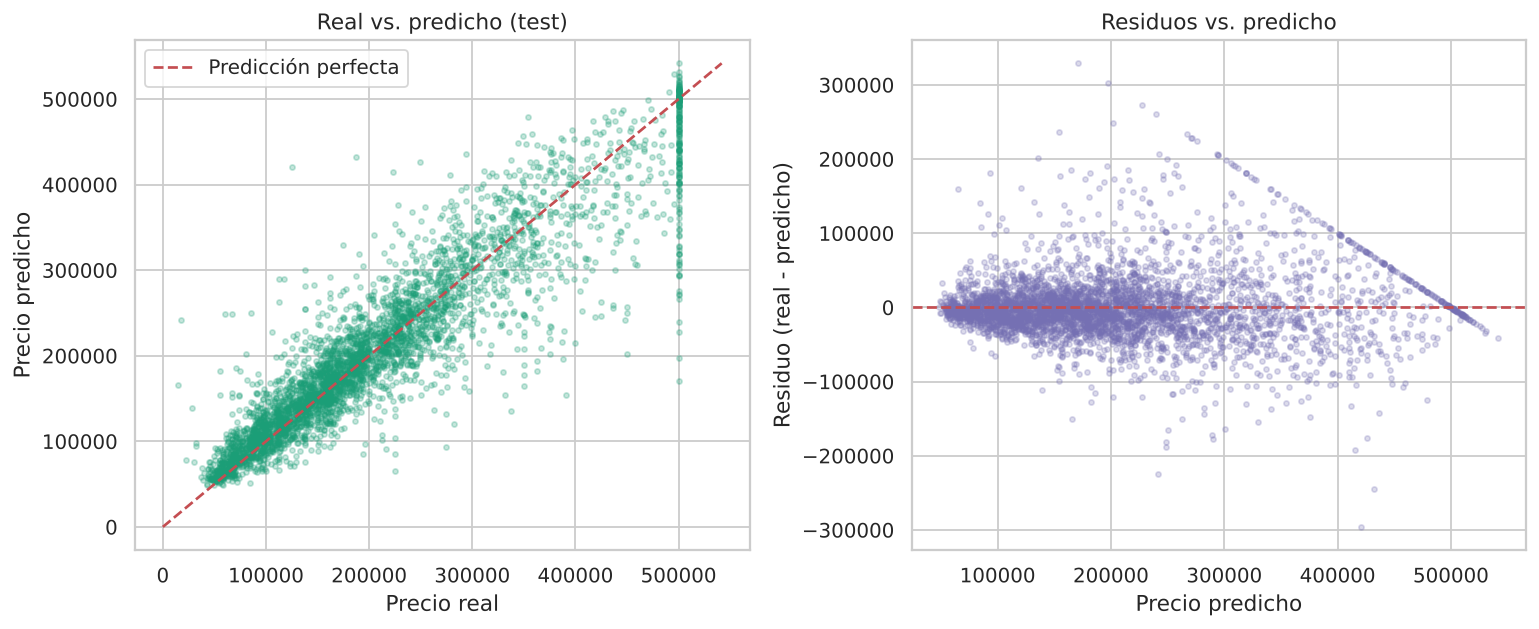

In [22]:
pred = best.predict(X_test)
ml.plot_predictions(y_test, pred)
display(Image(FIG_DIR / "09_real_vs_predicho.png"))

**Lectura:** los puntos se agrupan cerca de la diagonal roja (predicción perfecta). La línea vertical en 500 000 y la diagonal en los residuos son el efecto de los **precios topados**: el modelo no puede saber cuánto valen realmente esas casas.

### 6.6 ¿Qué variables importan? (importancia por permutación)
Se baraja una variable a la vez en el set de prueba y se mide cuánto **empeora** el error. Cuanto más empeora, más depende el modelo de esa variable.

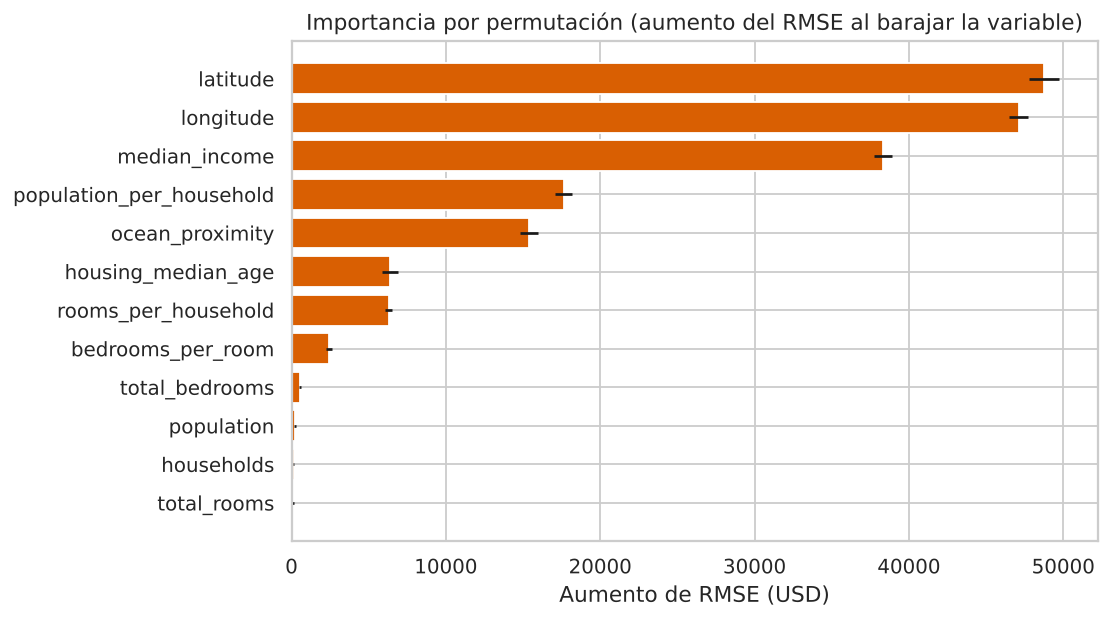

In [23]:
imp = ml.plot_importance(best, X_test, y_test)
display(Image(FIG_DIR / "10_importancia_variables.png"))

## 7. Conclusiones

1. **Mejor modelo:** Gradient Boosting ajustado, con R² ≈ 0,85 y error absoluto medio ≈ 29 000 USD en datos no vistos, frente a ≈ 90 000 USD del baseline.
2. **Los modelos de árboles superan claramente a los lineales** (RMSE ≈ 45 000 vs ≈ 69 000 USD): hay relaciones no lineales e interacciones (sobre todo geográficas).
3. **Variables clave:** latitud, longitud e ingreso mediano; la cercanía al océano y el hacinamiento (`population_per_household`) vienen después. Las variables creadas por nosotros aportan.
4. **Estadística:** el precio difiere de forma muy marcada según la cercanía al océano (d de Cohen ≈ −1,2 entre interior y <1H océano).

### Limitaciones (importante para ser honesto con los resultados)
- Datos de **1990**: sirve para aprender, no para decidir sobre el mercado actual.
- **Censura** en 500 001 (≈ 4,7 % de filas): subestima el error en viviendas caras.
- La unidad es el **distrito**, no la vivienda individual; no se debe extrapolar a casas concretas.
- Las predicciones espaciales no consideran autocorrelación geográfica (distritos vecinos se parecen); la validación aleatoria puede ser algo optimista.
- Categoría `ISLAND` con solo 5 filas: conclusiones sobre ella no son fiables.

### Próximos pasos posibles
- Probar `log(precio)` como objetivo, o excluir los distritos topados.
- Validación espacial (separar por zonas geográficas).
- Interpretabilidad con SHAP, y más variables (distancia a ciudades grandes).